In [1]:
import pandas as pd
import numpy as np
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

df = pd.read_csv('cars.csv')

In [2]:
df.head()

,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city,brand_rank,car_age
0,0,2016,Honda,Honda Brio S MT,Brio,"425,000.00","9,680.00",Petrol,Mumbai,7,5.00
1,1,2012,Nissan,Nissan Sunny XV Diesel,Sunny,"325,000.00","119,120.00",Diesel,Mumbai,11,9.00
2,2,2017,Toyota,Toyota Fortuner 2.8 4x2 MT [2016-2020],Fortuner,"2,650,000.00","64,593.00",Diesel,Thane,1,4.00
3,3,2017,Mercedes-Benz,Mercedes-Benz E-Class E 220d Expression [2019-...,E-Class,"4,195,000.00","25,000.00",Diesel,Mumbai,2,4.00
4,4,2012,Hyundai,Hyundai Verna Fluidic 1.6 CRDi SX,Verna,"475,000.00","23,800.00",Diesel,Mumbai,14,9.00


In [3]:
df.describe()

,Id,year,price,distance_travelled(kms),brand_rank,car_age
count,"1,725.00","1,725.00","1,725.00","1,725.00","1,725.00","1,725.00"
mean,862.00,"2,015.39","1,494,837.39","53,848.26",15.73,5.61
std,498.11,3.21,"1,671,657.73","44,725.54",12.95,3.21
min,0.00,"1,990.00","62,500.00",350.00,1.00,0.00
25%,431.00,"2,013.00","545,000.00","29,000.00",5.00,3.00
50%,862.00,"2,016.00","875,000.00","49,000.00",14.00,5.00
75%,"1,293.00","2,018.00","1,825,000.00","70,500.00",24.00,8.00
max,"1,724.00","2,021.00","14,700,000.00","790,000.00",81.00,31.00


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1725 entries, 0 to 1724
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Id                       1725 non-null   int64  
 1   year                     1725 non-null   int64  
 2   brand                    1725 non-null   str    
 3   full_model_name          1725 non-null   str    
 4   model_name               1725 non-null   str    
 5   price                    1725 non-null   float64
 6   distance_travelled(kms)  1725 non-null   float64
 7   fuel_type                1725 non-null   str    
 8   city                     1725 non-null   str    
 9   brand_rank               1725 non-null   int64  
 10  car_age                  1725 non-null   float64
dtypes: float64(3), int64(3), str(5)
memory usage: 148.4 KB


In [5]:
df.isnull().sum()

Id                         0
year                       0
brand                      0
full_model_name            0
model_name                 0
price                      0
distance_travelled(kms)    0
fuel_type                  0
city                       0
brand_rank                 0
car_age                    0
dtype: int64

In [6]:
#id column is of no use, we will drop it

df = df.drop('Id',axis=1)

In [7]:
categorical = df.select_dtypes(include='str').columns.tolist()

In [8]:
for col in categorical:
    num_dist = df[col].nunique()
    print(f"column name : {col:<20} , number of distinct values : {num_dist}")

column name : brand                , number of distinct values : 31
column name : full_model_name      , number of distinct values : 750
column name : model_name           , number of distinct values : 169
column name : fuel_type            , number of distinct values : 5
column name : city                 , number of distinct values : 15


In [9]:
#feature analysis for numerical columns
# we will use perason correlation matrix only

#actually I realized year is categorical although it represents numbers
target = df['price']

numeric = ['year','distance_travelled(kms)','brand_rank','car_age']

df_numeric = df[numeric]

df_numeric.corrwith(target)

#here you can see year and car_age are mutually exclusive compared to target value "price". exactly same value but opposite sign. so we can remove it.
#if you think about it, you knew age is just accumulating from year feature. considering 2024 this dataset is collected, age is just a number accumulating
#from year manufactured till 2024

year                       0.29
distance_travelled(kms)   -0.14
brand_rank                -0.16
car_age                   -0.29
dtype: float64

In [10]:
#feature analysis for categorical variables
#getting feature importance/weightage as per mutual information
#here we have categorical features and continous target variable so we need to use "mutual_info_regression"

from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import LabelEncoder

x_category_feat = df[categorical].copy()

for col in categorical:
    x_category_feat[col] = LabelEncoder().fit_transform(x_category_feat[col])

miscore = mutual_info_regression(x_category_feat,target,random_state=42)

miscore = pd.Series(miscore,index=categorical).sort_values(ascending=False)

miscore

full_model_name   1.28
model_name        1.03
brand             0.69
city              0.25
fuel_type         0.16
dtype: float64

In [11]:
#lets check if this full_model_name is highly inflated value bcoz of huge distinct values in that categorical column
#we will perform permutation_importance
#https://www.geeksforgeeks.org/machine-learning/machine-learning-explainability-using-permutation-importance/

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

x_train,x_val,y_train,y_val = train_test_split(x_category_feat,target,test_size=0.2,random_state=42)

rf = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10) # depth constraint prevents pure memorization
rf.fit(x_train, y_train)

result = permutation_importance(rf, x_val, y_val, n_repeats=5, random_state=42)

#result

feat_importance = pd.Series(result.importances_mean, index=categorical).sort_values(ascending=False)

print(feat_importance)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

full_model_name   0.76
brand             0.70
model_name        0.45
fuel_type         0.07
city              0.07
dtype: float64


<Figure size 800x800 with 0 Axes>

<Axes: xlabel='distance_travelled(kms)', ylabel='Count'>

Text(0.5, 0, 'feature values')

Text(0, 0.5, 'counts')

Text(0.5, 1.0, 'Histogram for column "distance_travelled(kms)"')

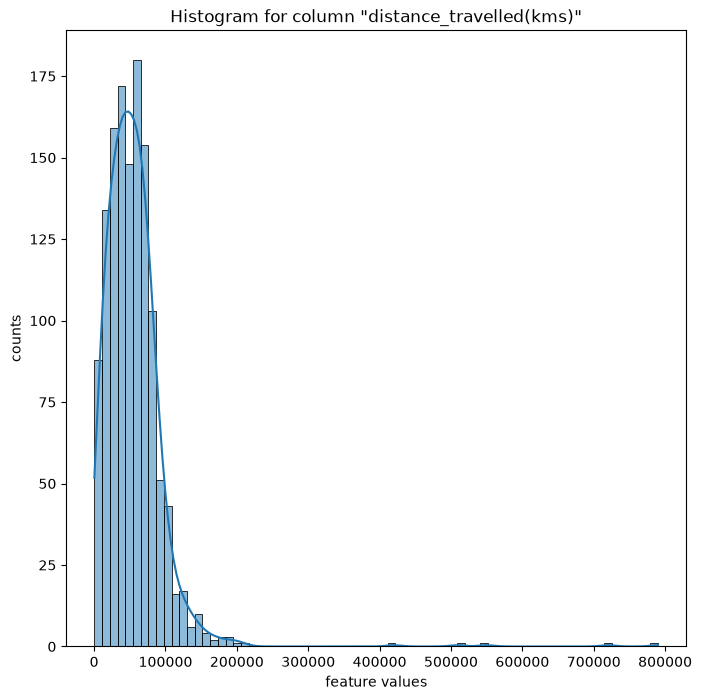

<Figure size 800x800 with 0 Axes>

<Axes: xlabel='brand_rank', ylabel='Count'>

Text(0.5, 0, 'feature values')

Text(0, 0.5, 'counts')

Text(0.5, 1.0, 'Histogram for column "brand_rank"')

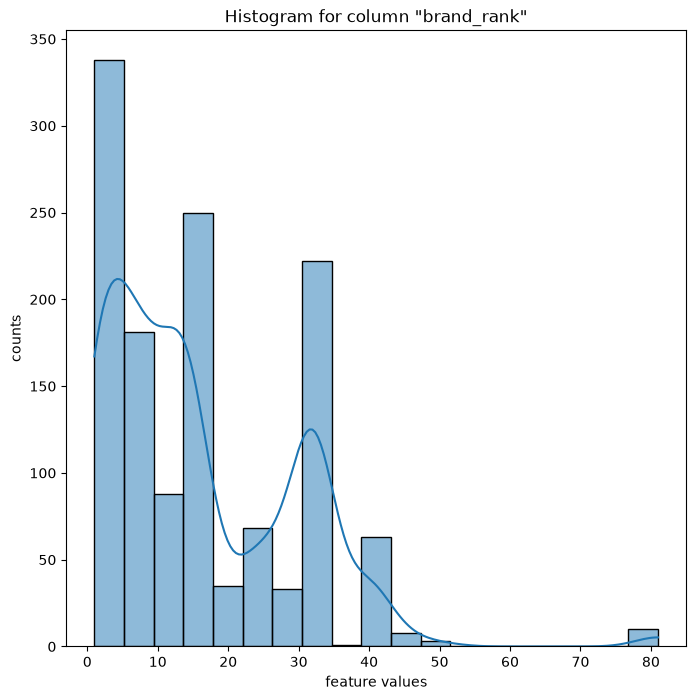

<Figure size 800x800 with 0 Axes>

<Axes: xlabel='car_age', ylabel='Count'>

Text(0.5, 0, 'feature values')

Text(0, 0.5, 'counts')

Text(0.5, 1.0, 'Histogram for column "car_age"')

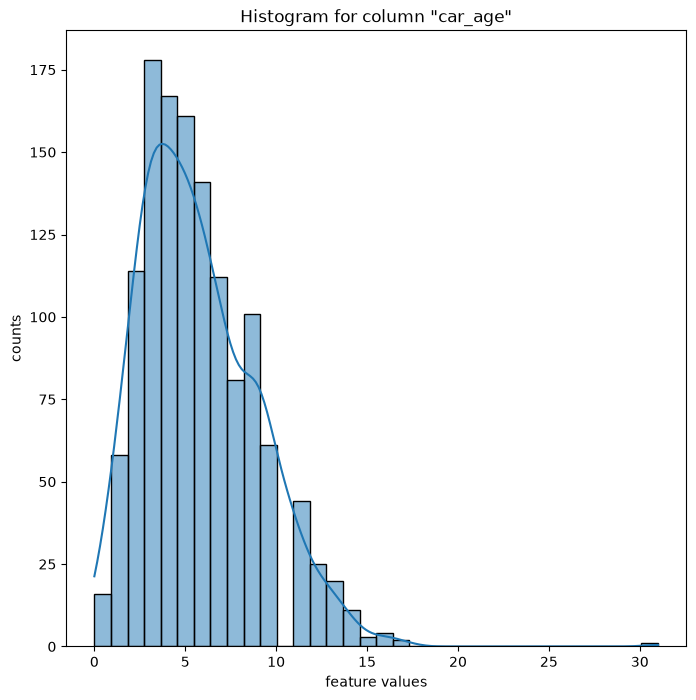

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
for col in numeric:
    plt.figure(figsize=(8,8))
    sns.histplot(df[col],kde=True);
    plt.xlabel('feature values')
    plt.ylabel('counts')
    plt.title(f'Histogram for column "{col}"')
    plt.show();

# I can see skewness (right tail) in distance travelled feature. brand_rank, age and year are okay, not many outliers, also, will drop year or age
# we dont need to scale feature "distance_travelled(kms)" because we are going to use tree based models like Randomforest and XGboost
# if we use any linear models like linear regression then we might need to scale the outliers

In [13]:
df[numeric].skew().sort_values()

target.skew()

year                      -0.94
car_age                    0.94
brand_rank                 1.19
distance_travelled(kms)    6.85
dtype: float64

np.float64(3.1689263313330707)

In [14]:
#looks like so many duplicates in this dataset, sorry I should have taken better dataset but I am 50% into this project 
#and dont want to redo the whole thing on better dataset
df = df.drop_duplicates().reset_index(drop=True)

df = df.drop('year',axis=1)

In [15]:
df.count()

brand                      1300
full_model_name            1300
model_name                 1300
price                      1300
distance_travelled(kms)    1300
fuel_type                  1300
city                       1300
brand_rank                 1300
car_age                    1300
dtype: int64

In [16]:
import re

patt = r'\b(at|mt|automatic|manual|multitronic|tiptronic|amt|cvt|dct|dsg)\b'

df['transmission'] = (
    df['full_model_name']
    .str.extract(patt, flags=re.IGNORECASE, expand=False)
    .str.upper()          # Normalize casing (e.g., 'Automatic' -> 'AUTOMATIC', 'at' -> 'AT')
    .fillna('UNKNOWN')     # Fill cars without an explicit tag (default to 'MANUAL' or 'UNKNOWN')
)

In [17]:
df['engine_litres'] = df['full_model_name'].str.extract(r'(\d\.\d)',expand=False)

df['engine_litres'] = (df['engine_litres']+'L').fillna('UNKNOWN')

In [18]:
df['engine_litres'].value_counts()

engine_litres
UNKNOWN    720
1.2L       138
1.5L        92
1.6L        79
2.0L        42
1.4L        38
1.0L        29
3.0L        28
2.5L        28
2.4L        27
2.8L        17
1.3L        10
1.1L        10
1.8L         9
2.2L         9
3.2L         8
5.0L         5
1.9L         4
2.7L         3
4.4L         3
2.6L         1
Name: count, dtype: int64

In [19]:
def clean_model_name(row):
    text = re.sub(rf'^{re.escape(row["brand"])}\s+', '', row['full_model_name'], flags=re.IGNORECASE)
    words = text.split()
    multi_word = {'7', '5', '3', '6', 'range', 'swift', 'grand', 'wagon', 'alto', 'innova', 'corolla', 'land', 'continental'}
    if len(words) >= 2 and words[0].lower() in multi_word:
        return f"{words[0]} {words[1]}"
    return words[0] if words else row['model_name']

df['model_name_clean'] = df.apply(clean_model_name, axis=1)


In [20]:
for col in ['engine_litres', 'transmission','model_name_clean']:
    if col not in categorical:
        categorical.append(col)

In [21]:
# will drop full_model_name column now, since it is inflating number of columns created after using DictVectorizer
df = df.drop('full_model_name',axis=1)

In [22]:
categorical

numeric

['brand',
 'full_model_name',
 'model_name',
 'fuel_type',
 'city',
 'engine_litres',
 'transmission',
 'model_name_clean']

['year', 'distance_travelled(kms)', 'brand_rank', 'car_age']

In [23]:
df['fuel_type'].value_counts()

fuel_type
Diesel        688
Petrol        599
CNG + 1         7
Petrol + 1      5
Hybrid          1
Name: count, dtype: int64

In [24]:
df['fuel_type'] = df['fuel_type'].str.replace(r'\s*\+\s*\d+', '', regex=True)

In [25]:
df[df['model_name']=='Zest']

,brand,model_name,price,distance_travelled(kms),fuel_type,city,brand_rank,car_age,transmission,engine_litres,model_name_clean
184,Tata,Zest,"495,000.00","61,649.00",Diesel,Thane,40,6.00,UNKNOWN,UNKNOWN,Zest
1147,Tata,Zest,"4,500,000.00","61,352.00",Petrol,Pune,40,5.00,UNKNOWN,UNKNOWN,Zest


In [26]:
#fixing the outlier value to some random close to real value
df.loc[(df['model_name']=='Zest') & (df['price'] > 495000.0),'price']=455000.0

In [27]:
from sklearn.feature_extraction import DictVectorizer
def prep_train(df):
    dicts = df.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)

    x_train = dv.fit_transform(dicts)

    return x_train,dv

def prep_val(df,dv):
    dicts = df.to_dict(orient='records')

    x_val = dv.transform(dicts)

    return x_val

In [28]:
#will try random forest first
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error, r2_score

scores = []

numeric = [num for num in numeric if num != 'year']
categorical = [cat for cat in categorical if (cat != 'full_model_name' and cat != 'model_name')]

x_train,x_val,y_train,y_val = train_test_split(df[categorical+numeric],df['price'],random_state=42)

train_df = x_train.copy()
train_df['price'] = y_train

global_median = y_train.median()
brand_medians = train_df.groupby('brand')['price'].median()
model_median = train_df.groupby('model_name_clean')['price'].median()

for split_df in (x_train,x_val):
    split_df['brand_median_price'] = split_df['brand'].map(brand_medians).fillna(global_median)
    split_df['model_median_price'] = split_df['model_name_clean'].map(model_median).fillna(split_df['brand_median_price'])
    split_df['depreciated_model_val'] = split_df['model_median_price'] / (split_df['car_age'] + 1)
    split_df['kms_per_year'] = split_df['distance_travelled(kms)'] / (split_df['car_age'] + 1)

    
x_train,dv = prep_train(x_train)
x_val = prep_val(x_val,dv)

y_train_log = np.log1p(y_train)

for n_est in [50,100,150,200,250]:
    rf_model = RandomForestRegressor(n_estimators=n_est,random_state=42,n_jobs=-1) # n_jobs is used to use all CPU thread available
    
    rf_model.fit(x_train,y_train_log)

    y_pred_log = rf_model.predict(x_val)

    y_pred = np.expm1(y_pred_log)
    
    rmse = root_mean_squared_error(y_val,y_pred)

    

    scores.append((n_est,round(rmse,2)))
    print(f"rmse for n_estimators {n_est} is {rmse}")
    print(f"MAE: {mean_absolute_error(y_val, y_pred):,.2f}")
    print(f"R2:  {r2_score(y_val, y_pred):.4f}")
    

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"ma

rmse for n_estimators 50 is 620656.4663211026
MAE: 279,161.90
R2:  0.8512


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

rmse for n_estimators 100 is 641024.2580380565
MAE: 281,820.10
R2:  0.8413


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

rmse for n_estimators 150 is 642785.292920955
MAE: 282,585.61
R2:  0.8404


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

rmse for n_estimators 200 is 652769.684063177
MAE: 284,173.69
R2:  0.8354


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

rmse for n_estimators 250 is 654390.456579524
MAE: 284,550.49
R2:  0.8346


In [29]:
# Assuming you kept the raw validation slice:

val_df = df.loc[y_val.index].copy()
val_df['pred'] = y_pred
val_df['abs_err'] = (val_df['price'] - val_df['pred']).abs()
val_df.sort_values('abs_err', ascending=False).head(10)


,brand,model_name,price,distance_travelled(kms),fuel_type,city,brand_rank,car_age,transmission,engine_litres,model_name_clean,pred,abs_err
331,BMW,7,"12,100,000.00","12,000.00",Petrol,Delhi,4,1.00,UNKNOWN,UNKNOWN,7 Series,"7,287,605.09","4,812,394.91"
361,Land Rover,Sport,"12,300,000.00","17,000.00",Diesel,Delhi,18,2.00,UNKNOWN,3.0L,Range Rover,"8,098,757.72","4,201,242.28"
894,Volvo,XC60,"5,600,000.00","40,000.00",Diesel,Chennai,9,2.00,UNKNOWN,UNKNOWN,XC60,"1,547,265.83","4,052,734.17"
1241,MINI,Cooper,"5,300,000.00",700.00,Petrol,Pune,39,2.00,UNKNOWN,UNKNOWN,Cooper,"2,392,957.85","2,907,042.15"
1062,Audi,A4,"4,400,000.00","16,000.00",Diesel,Chennai,10,1.00,UNKNOWN,UNKNOWN,A4,"1,678,279.98","2,721,720.02"
155,Volvo,V40,"1,750,000.00","78,000.00",Diesel,Dehradun,9,5.00,UNKNOWN,UNKNOWN,V40,"4,286,717.75","2,536,717.75"
676,Mercedes-Benz,GLE,"8,500,000.00","26,000.00",Petrol,Hyderabad,2,3.00,UNKNOWN,UNKNOWN,GLE,"6,064,834.02","2,435,165.98"
63,BMW,Z4,"4,850,000.00","26,700.00",Petrol,Dehradun,4,5.00,UNKNOWN,UNKNOWN,Z4,"2,462,070.22","2,387,929.78"
682,Audi,Q7,"6,700,000.00","37,914.00",Diesel,Hyderabad,10,4.00,UNKNOWN,UNKNOWN,Q7,"4,557,884.10","2,142,115.90"
44,Mercedes-Benz,E-Class,"3,850,000.00","6,000.00",Petrol,Mumbai,2,8.00,UNKNOWN,UNKNOWN,E-Class,"1,792,134.09","2,057,865.91"
